<a href="https://colab.research.google.com/github/Chaehyeon1125/ESW4024_41_Introduction_to_Recommendation_Systems/blob/main/RS_HW1_2023313623_Chaehyeon_Lee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **(0) 환경설정 및 이모저모: Note 1, 2**

In [1]:
# 0. Note 1: RecBole library 설치
%pip install --no-deps "git+https://github.com/RUCAIBox/RecBole.git@v1.2.1"

  Cloning https://github.com/RUCAIBox/RecBole.git (to revision v1.2.1) to /tmp/pip-req-build-7kjfetbf
  Running command git clone --filter=blob:none --quiet https://github.com/RUCAIBox/RecBole.git /tmp/pip-req-build-7kjfetbf
  Running command git checkout -q 9a6f63d8d4a5b989fe27955a833f813a6d86041e
  Resolved https://github.com/RUCAIBox/RecBole.git to commit 9a6f63d8d4a5b989fe27955a833f813a6d86041e
  Preparing metadata (setup.py) ... done


In [1]:
# 0. Note 2: 실행 함수 불러오기
# NumPy 호환성 설정은 Colab에서 실행하기 위해 추가함
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import inspect

# NumPy 2.x 호환성 설정
np.float_ = np.float64
np.complex_ = np.complex128
np.unicode_ = np.str_

from recbole.quick_start import run_recbole
from recbole.model.general_recommender.itemknn import ItemKNN

assert 'config["knn_method"]' in inspect.getsource(ItemKNN.__init__), \
    "세션을 다시 시작한 뒤 셀2를 실행해."

print("준비 완료: ItemKNN / UserKNN 전환 지원")

준비 완료: ItemKNN / UserKNN 전환 지원


# **(1) Neighborhood-based CF (KNN)**

In [2]:
# 1.1 두 모델을 지정된 데이터와 k 값으로 실행하고 평가 결과 수집

k_values = [1, 5, 10, 100, 500]
rows = []

common_config = {
    "seed": 2020,
    "reproducibility": True,
    "use_gpu": False,
    "show_progress": False,
    "eval_args": {
        "split": {"RS": [0.8, 0.1, 0.1]},
        "group_by": "user",
        "order": "RO",
        "mode": "full"
    },
    "metrics": ["Recall", "MRR", "NDCG", "Hit", "Precision"],
    "topk": [10],
    "valid_metric": "NDCG@10",
    "shrink": 0.0
}

for method, model_name in [("item", "ItemKNN"), ("user", "UserKNN")]:
    for k in k_values:
        print(f"실행 중: {model_name}, k={k}")

        config = {
            **common_config,
            "knn_method": method,
            "k": k
        }

        result = run_recbole(
            model="ItemKNN",
            dataset="ml-100k",
            config_dict=config,
            saved=False
        )

        row = {
            "model": model_name,
            "k": k,
            "valid_ndcg@10": float(
                result["best_valid_result"]["ndcg@10"]
            )
        }

        row.update({
            metric: float(value)
            for metric, value in result["test_result"].items()
        })

        rows.append(row)

        results_df = pd.DataFrame(rows)
        results_df.to_csv("knn_results.csv", index=False)

        print(f"완료: Test NDCG@10 = {row['ndcg@10']:.4f}\n")

display(results_df.round(4))

실행 중: ItemKNN, k=1


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Test NDCG@10 = 0.1973

실행 중: ItemKNN, k=5


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Test NDCG@10 = 0.2320

실행 중: ItemKNN, k=10


...

/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Test NDCG@10 = 0.2878

실행 중: UserKNN, k=500


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Test NDCG@10 = 0.2471



,model,k,valid_ndcg@10,recall@10,mrr@10,ndcg@10,hit@10,precision@10
0,ItemKNN,1,0.1727,0.1742,0.3465,0.1973,0.6691,0.1367
1,ItemKNN,5,0.1993,0.2069,0.4023,0.2320,0.7338,0.1592
2,ItemKNN,10,0.2108,0.2316,0.4240,0.2527,0.7741,0.1748
3,ItemKNN,100,0.2214,0.2469,0.4630,0.2835,0.7847,0.1930
4,ItemKNN,500,0.2222,0.2356,0.4585,0.2747,0.7561,0.1810
5,UserKNN,1,0.1037,0.1142,0.1743,0.1036,0.5154,0.0786
6,UserKNN,5,0.1715,0.1937,0.3394,0.1988,0.7094,0.1361
7,UserKNN,10,0.2022,0.2200,0.4017,0.2394,0.7487,0.1602
8,UserKNN,100,0.2349,0.2451,0.4844,0.2878,0.7815,0.1883
9,UserKNN,500,0.2012,0.2123,0.4320,0.2471,0.7444,0.1619


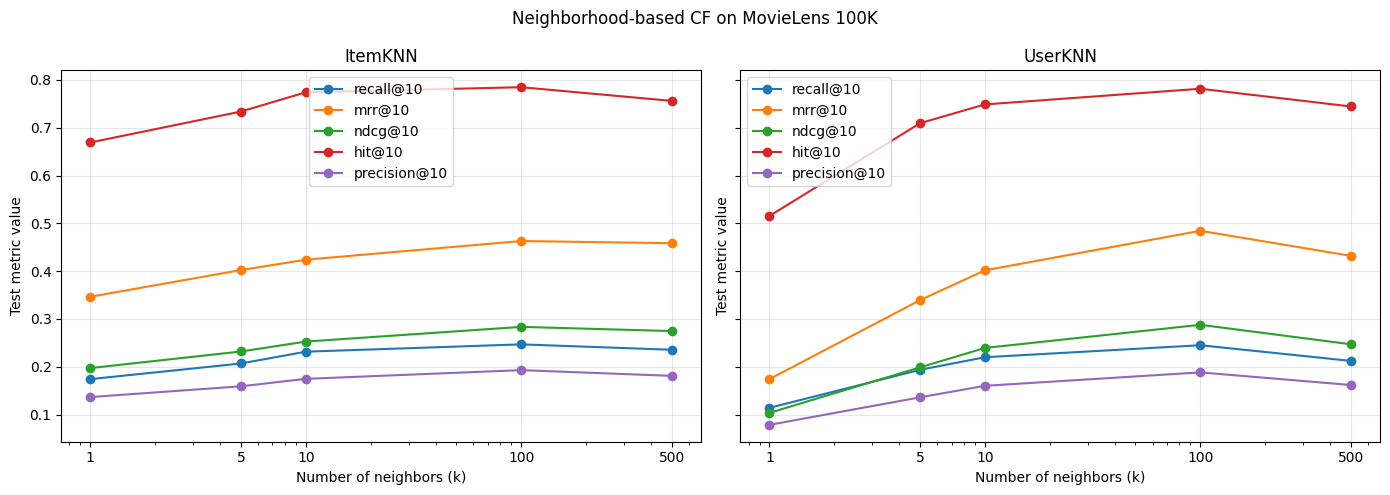

In [3]:
# 1.2 각 모델의 k별 평가 지표 그래프 생성
metrics = ["recall@10", "mrr@10", "ndcg@10", "hit@10", "precision@10"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, model_name in zip(axes, ["ItemKNN", "UserKNN"]):
    subset = results_df[
        results_df["model"] == model_name
    ].sort_values("k")

    for metric in metrics:
        ax.plot(
            subset["k"],
            subset[metric],
            marker="o",
            label=metric
        )

    # k 간격이 크므로 로그 축 사용
    ax.set_xscale("log")
    ax.set_xticks(k_values)
    ax.set_xticklabels(k_values)
    ax.set_xlabel("Number of neighbors (k)")
    ax.set_ylabel("Test metric value")
    ax.set_title(model_name)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Neighborhood-based CF on MovieLens 100K")
plt.tight_layout()
plt.savefig("knn_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

# **(2) Latent Factor Model (BPR)**

In [4]:
# 2.1 BPR 학습 + hyperparameter 실험
import torch
from pathlib import Path

from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.model.general_recommender.bpr import BPR
from recbole.trainer import Trainer
from recbole.utils import init_seed


# 기존 BPR에 batch 평균 squared L2 penalty 추가
class BPRWithL2(BPR):
    def __init__(self, config, dataset):
        super().__init__(config, dataset)
        self.reg_lambda = config["reg_lambda"]

    def calculate_loss(self, interaction):
        user_e = self.get_user_embedding(interaction[self.USER_ID])
        pos_e = self.get_item_embedding(interaction[self.ITEM_ID])
        neg_e = self.get_item_embedding(interaction[self.NEG_ITEM_ID])

        pos_score = (user_e * pos_e).sum(dim=1)
        neg_score = (user_e * neg_e).sum(dim=1)

        ranking_loss = self.loss(pos_score, neg_score)

        l2_loss = 0.5 * (
            user_e.square().sum(dim=1)
            + pos_e.square().sum(dim=1)
            + neg_e.square().sum(dim=1)
        ).mean()

        return ranking_loss + self.reg_lambda * l2_loss


def run_bpr(embedding_size, reg_lambda):
    config = Config(
        model="BPR",
        dataset="ml-100k",
        config_dict={
            "embedding_size": embedding_size,
            "reg_lambda": reg_lambda,

            "seed": 2020,
            "reproducibility": True,
            "use_gpu": torch.cuda.is_available(),
            "show_progress": False,

            "epochs": 100,
            "stopping_step": 10,
            "eval_step": 1,
            "learner": "adam",
            "learning_rate": 0.001,
            "weight_decay": 0.0,
            "train_batch_size": 2048,

            "train_neg_sample_args": {
                "distribution": "uniform",
                "sample_num": 1,
                "alpha": 1.0,
                "dynamic": False,
                "candidate_num": 0
            },

            "eval_args": {
                "split": {"RS": [0.8, 0.1, 0.1]},
                "group_by": "user",
                "order": "RO",
                "mode": "full"
            },
            "metrics": ["NDCG"],
            "topk": [10],
            "valid_metric": "NDCG@10",
            "checkpoint_dir": (
                f"saved_bpr/d{embedding_size}_reg{reg_lambda}"
            )
        }
    )

    # 모든 조건에서 같은 데이터 분할 사용
    init_seed(config["seed"], config["reproducibility"])
    dataset = create_dataset(config)
    train_data, valid_data, test_data = data_preparation(config, dataset)

    # 모델 초기화와 학습의 seed 고정
    init_seed(config["seed"], config["reproducibility"])
    model = BPRWithL2(config, train_data.dataset).to(config["device"])
    trainer = Trainer(config, model)

    _, best_valid_result = trainer.fit(
        train_data, valid_data, saved=True, show_progress=False
    )

    # 이번 실행에서 직접 저장한 최상의 검증 checkpoint 복원
    checkpoint = torch.load(
        trainer.saved_model_file,
        map_location=config["device"],
        weights_only=False
    )
    model.load_state_dict(checkpoint["state_dict"])

    test_result = trainer.evaluate(
        test_data, load_best_model=False, show_progress=False
    )

    return {
        "embedding_size": embedding_size,
        "reg_lambda": reg_lambda,
        "valid_ndcg@10": float(best_valid_result["ndcg@10"]),
        "test_ndcg@10": float(test_result["ndcg@10"])
    }


# (64, 0.1)은 두 실험에 공통이므로 한 번만 실행
conditions = [
    (32, 0.1),
    (64, 0.1),
    (128, 0.1),
    (256, 0.1),
    (64, 0.01),
    (64, 0.5)
]

bpr_rows = []
print("사용 장치:", "GPU" if torch.cuda.is_available() else "CPU")

for embedding_size, reg_lambda in conditions:
    print(f"실행 중: embedding={embedding_size}, lambda={reg_lambda}")

    row = run_bpr(embedding_size, reg_lambda)
    bpr_rows.append(row)

    bpr_results_df = pd.DataFrame(bpr_rows)
    bpr_results_df.to_csv("bpr_results.csv", index=False)

    print(
        f"완료: Valid NDCG@10={row['valid_ndcg@10']:.4f}, "
        f"Test NDCG@10={row['test_ndcg@10']:.4f}\n"
    )

display(bpr_results_df.round(4))

사용 장치: CPU
실행 중: embedding=32, lambda=0.1


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Valid NDCG@10=0.1790, Test NDCG@10=0.2225

실행 중: embedding=64, lambda=0.1


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Valid NDCG@10=0.1841, Test NDCG@10=0.2305

실행 중: embedding=128, lambda=0.1


...

/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Valid NDCG@10=0.2397, Test NDCG@10=0.3032

실행 중: embedding=64, lambda=0.5


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: Valid NDCG@10=0.0957, Test NDCG@10=0.1060



,embedding_size,reg_lambda,valid_ndcg@10,test_ndcg@10
0,32,0.10,0.1790,0.2225
1,64,0.10,0.1841,0.2305
2,128,0.10,0.1857,0.2258
3,256,0.10,0.1783,0.2213
4,64,0.01,0.2397,0.3032
5,64,0.50,0.0957,0.1060


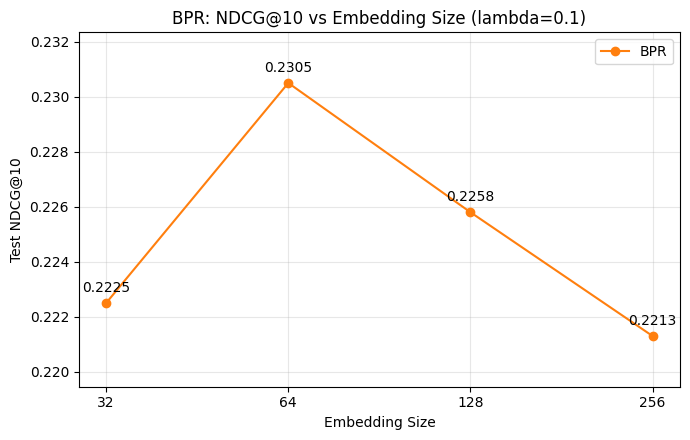

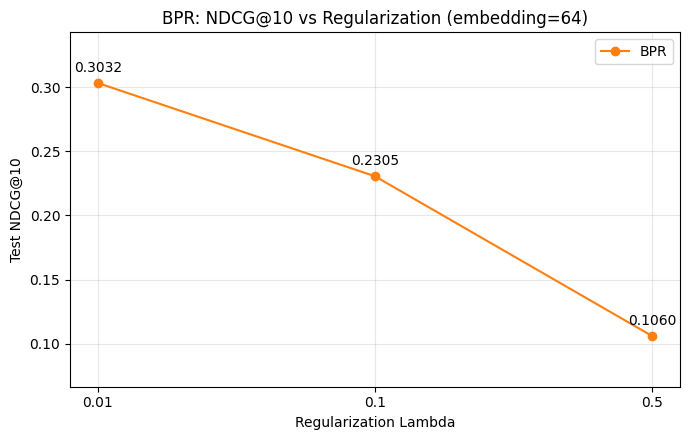

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# 2.2 BPR 실험 조건별 Test NDCG@10 그래프 생성
embedding_results = bpr_results_df[
    bpr_results_df["reg_lambda"] == 0.1
].sort_values("embedding_size")

regularization_results = bpr_results_df[
    bpr_results_df["embedding_size"] == 64
].sort_values("reg_lambda")

plot_specs = [
    (
        embedding_results,
        "embedding_size",
        "Embedding Size",
        "BPR: NDCG@10 vs Embedding Size (lambda=0.1)",
        "bpr_embedding_ndcg.png"
    ),
    (
        regularization_results,
        "reg_lambda",
        "Regularization Lambda",
        "BPR: NDCG@10 vs Regularization (embedding=64)",
        "bpr_regularization_ndcg.png"
    )
]

for data, x_column, x_label, title, filename in plot_specs:
    fig, ax = plt.subplots(figsize=(7, 4.5))

    positions = np.arange(len(data))
    values = data["test_ndcg@10"].to_numpy()

    ax.plot(positions, values, marker="o", color="tab:orange", label="BPR")
    ax.set_xticks(positions)
    ax.set_xticklabels(data[x_column].tolist())
    ax.set_xlabel(x_label)
    ax.set_ylabel("Test NDCG@10")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.margins(y=0.2)

    for x, y in zip(positions, values):
        ax.annotate(
            f"{y:.4f}", (x, y),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center"
        )

    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

from google.colab import files

files.download("bpr_embedding_ndcg.png")
files.download("bpr_regularization_ndcg.png")
files.download("bpr_results.csv")

# **(3) Item-to-item CF (SLIM, EASE)**

In [6]:
# 3.1 SLIM, EASE 실행 & ItemKNN과 성능 비교

# 실험1과 동일한 데이터 분할·seed·평가 조건
item_cf_config = {
    "seed": 2020,
    "reproducibility": True,
    "use_gpu": False,
    "show_progress": False,

    "eval_args": {
        "split": {"RS": [0.8, 0.1, 0.1]},
        "group_by": "user",
        "order": "RO",
        "mode": "full"
    },

    "metrics": ["Recall", "MRR", "NDCG", "Hit", "Precision"],
    "topk": [10],
    "valid_metric": "NDCG@10"
}

# 실험1에서 검증 NDCG가 가장 높았던 ItemKNN 선택
itemknn_rows = results_df[
    results_df["model"] == "ItemKNN"
]

best_itemknn = itemknn_rows.loc[
    itemknn_rows["valid_ndcg@10"].idxmax()
]

comparison_rows = [{
    "model": "ItemKNN",
    "settings": f"k={int(best_itemknn['k'])}",
    "valid_ndcg@10": float(best_itemknn["valid_ndcg@10"]),
    **{
        metric: float(best_itemknn[metric])
        for metric in [
            "recall@10", "mrr@10", "ndcg@10",
            "hit@10", "precision@10"
        ]
    }
}]

# 공식 문서의 기본 hyperparameters
model_settings = [
    (
        "SLIMElastic",
        "SLIM",
        {
            "alpha": 0.2,
            "l1_ratio": 0.02,
            "positive_only": True,
            "hide_item": True
        },
        "alpha=0.2, l1_ratio=0.02, positive_only=True, hide_item=True"
    ),
    (
        "EASE",
        "EASE",
        {"reg_weight": 250.0},
        "reg_weight=250"
    )
]

for model_name, display_name, parameters, settings_text in model_settings:
    print(f"실행 중: {display_name}")

    result = run_recbole(
        model=model_name,
        dataset="ml-100k",
        config_dict={**item_cf_config, **parameters},
        saved=False
    )

    row = {
        "model": display_name,
        "settings": settings_text,
        "valid_ndcg@10": float(
            result["best_valid_result"]["ndcg@10"]
        ),
        **{
            metric: float(value)
            for metric, value in result["test_result"].items()
        }
    }

    comparison_rows.append(row)
    item_cf_results_df = pd.DataFrame(comparison_rows)
    item_cf_results_df.to_csv("item_cf_results.csv", index=False)

    print(
        f"완료: {display_name}, "
        f"Test NDCG@10={row['ndcg@10']:.4f}\n"
    )

display(item_cf_results_df.round(4))

from google.colab import files
files.download("item_cf_results.csv")

실행 중: SLIM


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: SLIM, Test NDCG@10=0.3236

실행 중: EASE


/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a c

완료: EASE, Test NDCG@10=0.3295



,model,settings,valid_ndcg@10,recall@10,mrr@10,ndcg@10,hit@10,precision@10
0,ItemKNN,k=500,0.2222,0.2356,0.4585,0.2747,0.7561,0.1810
1,SLIM,"alpha=0.2, l1_ratio=0.02, positive_only=True, ...",0.2553,0.2750,0.5231,0.3236,0.8123,0.2165
2,EASE,reg_weight=250,0.2563,0.2805,0.5277,0.3295,0.8197,0.2206


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>